# ResNet-50: ajuste, ejecución definitiva y evaluación

Este notebook entrena y evalúa ResNet-50 con las funciones de `src/` (`train.py`, `tune.py`,
`final.py`, `results.py`, `evaluation.py`, `gradcam.py`). El modelo se elige con la variable
`MODELO` de la sección 1; el resto del notebook es igual para los tres modelos base. Todos los
parámetros se leen de `configs/base.yaml` y `configs/<modelo>.yaml`. El ajuste usa
solo los pliegues de entrenamiento; test se evalúa únicamente en la ejecución definitiva. Si
faltan resultados, cada sección muestra un aviso y el notebook continúa.

## 1. Configuración

Modelo y flags de reejecución. Con un flag en `False`, la sección correspondiente carga los
resultados guardados y, si no existen, muestra un aviso sin ejecutar nada. Con `True`, llama a
`src.tune` o `src.final`, que reutilizan las corridas terminadas y ejecutan las pendientes.

In [1]:
MODELO = "resnet50"
RERUN_AJUSTE = False
RERUN_FINAL = False

In [2]:
import pandas as pd

from src import data, evaluation, final, gradcam, results
from src.report import show
from src.train import build_model, configure_runtime, load_model_config
from src.tune import run_tuning
from src.utils import environment_info, set_seed

Carga de las configuraciones, memory growth en la GPU, política de precisión
(`train.mixed_precision`) y semilla (`seed` de `base.yaml`).

In [3]:
cfg = data.load_config()
cfg_modelo = load_model_config(MODELO)
configure_runtime(cfg)
set_seed(cfg["seed"], deterministic=cfg["train"]["deterministic"])
rutas = cfg["paths"]
cfg_train = cfg["train"]
cfg_eval = cfg["evaluation"]
ALPHA = cfg["benchmark"]["alpha"]

pd.Series({
    "modelo": cfg_modelo["name"],
    "aplicación de Keras": cfg_modelo["keras_application"],
    "pesos": cfg_modelo["weights"],
    "entrada": f"{cfg_modelo['input_size']} x {cfg_modelo['input_size']}",
    "capa de Grad-CAM": cfg_modelo.get("gradcam_layer"),
    "clases": ", ".join(data.class_names(cfg)),
    "batch_size": cfg_train["batch_size"],
    "mixed_precision": cfg_train["mixed_precision"],
    "deterministic": cfg_train["deterministic"],
    "épocas fase A": cfg_train["warmup"]["epochs"],
    "épocas máximas fase B": cfg_train["finetune"]["max_epochs"],
    "semilla del notebook": cfg["seed"],
}, name="valor").to_frame()

2026-11-28 05:32:36.460624: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


,valor
modelo,resnet50
aplicación de Keras,ResNet50
pesos,imagenet
entrada,224 x 224
capa de Grad-CAM,conv5_block3_out
clases,"akiec, bcc, bkl, df, mel, nv, vasc"
batch_size,32
mixed_precision,True
deterministic,False
épocas fase A,5


GPU detectada y versiones de Python, TensorFlow, Keras, CUDA y cuDNN (estas dos, las de
compilación de TensorFlow).

In [4]:
results.environment_table(environment_info())

,valor
python,3.11.18
tensorflow,2.20.0
keras,3.15.1
cuda,12.5.1
cudnn,9
platform,Linux-7.2.11-300.fc45.x86_64-x86_64-with-glibc...
gpu,ninguna


## 2. Modelo

Arquitectura: entrada en [0, 255], `preprocess_input` de la aplicación dentro del modelo, backbone
anidado con `training=False` y cabeza: `GlobalAveragePooling2D`, `Dropout` y `Dense` softmax en float32, la cabeza nativa de ResNet-50 con la capa de 1000 clases sustituida. El backbone son los bloques convolucionales de `ResNet50(include_top=False)`. El dropout es el del YAML, o 0.0 si aún es null
(no cambia el número de parámetros).

In [5]:
modelo = build_model(cfg, MODELO)
modelo.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Lambda)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ backbone (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 7)              │        14,343 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,602,055 (90.03 MB)

 Trainable params: 14,343 (56.03 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Parámetros entrenables y no entrenables con el backbone congelado (fase A) y descongelado (fase B).
Los no entrenables restantes en la fase B son las medias y varianzas móviles de BatchNormalization.

In [6]:
results.model_parameter_table(modelo)

,trainable,non_trainable,total
backbone congelado,14343,23587712,23602055
backbone descongelado,23548935,53120,23602055


## 3. Ajuste de hiperparámetros

Búsqueda aleatoria de `train.tuning`: `n_trials` configuraciones muestreadas con `sampler_seed`
(las mismas para los tres modelos), una corrida por configuración con `seed` y `val_fold` fijos y la
fase B limitada a `tuning.max_epochs`.

In [7]:
pd.DataFrame(cfg_train["tuning"]["space"]).T

,type,low,high,values
learning_rate,loguniform,0.00001,0.001,NaN
weight_decay,loguniform,0.000001,0.001,NaN
dropout,choice,NaN,NaN,"[0.0, 0.2, 0.4]"


### 3.1 Ejecución

Carga `outputs/tuning/<modelo>/trials.csv` si existe; con `RERUN_AJUSTE = True`, llama a
`run_tuning`. Si el ajuste se interrumpió, el archivo contiene solo los ensayos terminados.

In [8]:
dir_ajuste = rutas["tuning_dir"] / MODELO
ensayos, origen = results.load_or_run(
    dir_ajuste / "trials.csv", lambda: run_tuning(cfg, MODELO), RERUN_AJUSTE,
    missing_message=f"no hay ensayos de ajuste de {MODELO}; ejecuta `python -m src.tune --model {MODELO}` "
                    "o pon RERUN_AJUSTE = True.")
results.load_status(dir_ajuste / "trials.csv", ensayos, origen, "ensayos")

,valor
archivo,outputs/tuning/resnet50/trials.csv
estado,cargado
ensayos,6


### 3.2 Resultados

Configuraciones ordenadas por exactitud balanceada de validación (`best_epoch` es la época de la
fase B cuyos pesos se restauraron).

In [9]:
results.tuning_table(ensayos)

,trial,learning_rate,weight_decay,dropout,val_balanced_accuracy,best_epoch,epochs_warmup,epochs_finetune,train_time_s,run_dir,excluded,excluded_reason
0,3,0.000202,0.000008,0.0,0.759633,8,5,13,634.290651,outputs/runs/resnet50/tuning_t03/s0_f0,False,NaN
1,5,0.000320,0.000035,0.2,0.723654,10,5,15,744.432515,outputs/runs/resnet50/tuning_t05/s0_f0,False,NaN
2,2,0.000381,0.000519,0.4,0.718954,14,5,15,723.870045,outputs/runs/resnet50/tuning_t02/s0_f0,False,NaN
3,0,0.000023,0.000083,0.2,0.685451,10,5,15,762.529294,outputs/runs/resnet50/tuning_t00/s0_f0,False,NaN
4,1,0.000055,0.000012,0.2,0.680940,5,5,10,519.699464,outputs/runs/resnet50/tuning_t01/s0_f0,False,NaN
5,4,0.000859,0.000575,0.0,0.627170,15,5,15,724.211021,outputs/runs/resnet50/tuning_t04/s0_f0,False,NaN


Mejor configuración según `best.json` (se escribe al terminar todos los ensayos).

In [10]:
mejor = results.load_json_or_missing(
    dir_ajuste / "best.json",
    f"no existe outputs/tuning/{MODELO}/best.json; se escribe al terminar `python -m src.tune --model {MODELO}`.")
results.best_table(mejor)

,valor
ensayo,3.000000
learning_rate,0.000202
weight_decay,0.000008
dropout,0.000000
val_balanced_accuracy,0.759633
best_epoch,8.000000


Exactitud balanceada de validación frente a cada hiperparámetro (eje logarítmico para los de
distribución loguniforme). El número junto a cada punto es el índice del ensayo; el círculo rojo
marca el mejor.

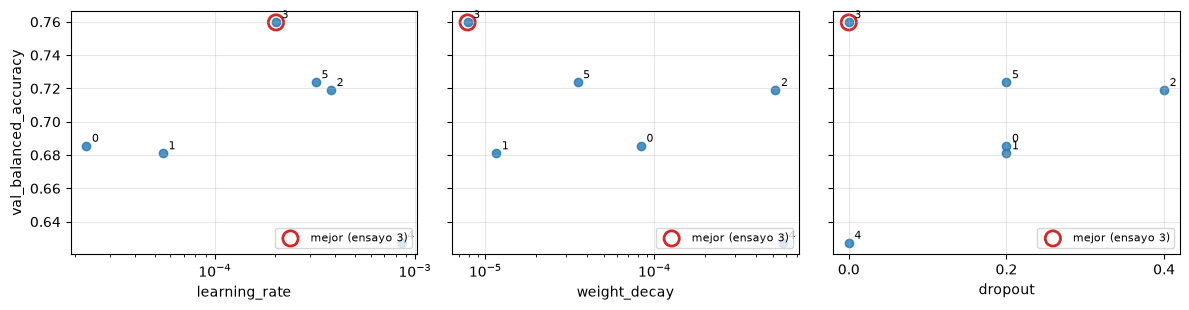

In [11]:
show(results.plot_metric_vs_hparams(ensayos, cfg_train["tuning"]["space"], best_trial=results.best_trial(mejor)))

### 3.3 Hiperparámetros seleccionados

Valores de la sección `hyperparameters` de `configs/<modelo>.yaml` frente a `best.json`. Se emite
un aviso si alguno es null o difiere.

In [12]:
results.compare_hparams(cfg_modelo, mejor)

/tmp/ipykernel_226722/1570348254.py:1: UserWarning: configs/resnet50.yaml: learning_rate (null en el YAML), weight_decay (null en el YAML), dropout (null en el YAML)
  results.compare_hparams(cfg_modelo, mejor)


,yaml,best.json,estado
learning_rate,None,0.000202,null en el YAML
weight_decay,None,0.000008,null en el YAML
dropout,None,0.0,null en el YAML


## 4. Estudio piloto

Estudio piloto omitido (desviación D2, capítulo 7).

## 5. Ejecución definitiva

Validación cruzada repetida: producto `final.seeds` x `final.folds` de `base.yaml`, con los
hiperparámetros del YAML del modelo. Cada corrida evalúa validación y test, calcula las métricas de
su train sin aumento ni dropout y guarda sus pesos. El número de semillas se fijó por cómputo en `preregistro.md`
(desviación D3, capítulo 7).

In [13]:
final.config_table(cfg)

,valor
etiqueta,final
semillas,[0]
pliegues,"[0, 1, 2, 3, 4]"
corridas,5
evaluación de test,True
métricas de train sin aumento,True
pesos guardados,True


### 5.1 Ejecución

Con `RERUN_FINAL = False`, carga las corridas definitivas terminadas sin ejecutar nada; con `True`,
llama a `run_final`, que reutiliza las terminadas y ejecuta las pendientes (equivale a
`python -m src.final --model <modelo>`). Resumen y estado de cada corrida prevista.

In [14]:
corridas, estado = final.load_or_run_final(cfg, MODELO, rerun=RERUN_FINAL)
show(results.runs_summary(corridas))
final.status_summary(estado)

,valor
corridas terminadas,5
corridas,"s0_f0, s0_f1, s0_f2, s0_f3, s0_f4"


,corridas
previstas,5
terminadas,5
pendientes,0


In [15]:
estado

,seed,val_fold,estado,run_dir
0,0,0,terminada,outputs/runs/resnet50/final/s0_f0
1,0,1,terminada,outputs/runs/resnet50/final/s0_f1
2,0,2,terminada,outputs/runs/resnet50/final/s0_f2
3,0,3,terminada,outputs/runs/resnet50/final/s0_f3
4,0,4,terminada,outputs/runs/resnet50/final/s0_f4


### 5.2 Resultados por corrida

Métricas globales de validación por corrida con los pesos restaurados. Al final, media, desviación
estándar (ddof = 1) e intervalo de confianza al 95 % de la media por t de Student
(`ci95_low`, `ci95_high`).

In [16]:
results.add_summary_rows(results.run_metrics_table(corridas, split="val"), alpha=ALPHA)

,balanced_accuracy,accuracy,f1_macro,f1_weighted,auc_roc_macro_ovr,auc_pr_macro,mcc,ece
s0_f0,0.744615,0.668608,0.609043,0.703057,0.951491,0.722798,0.537966,0.148159
s0_f1,0.735339,0.718695,0.613864,0.747029,0.952554,0.750749,0.566340,0.075458
s0_f2,0.745689,0.739662,0.672626,0.760703,0.951672,0.727077,0.596890,0.045659
s0_f3,0.693414,0.712289,0.629636,0.738565,0.946850,0.732811,0.549148,0.090792
s0_f4,0.740217,0.694639,0.643051,0.726162,0.955787,0.756773,0.553438,0.104718
mean,0.731855,0.706779,0.633644,0.735103,0.951671,0.738042,0.560756,0.092957
std,0.021875,0.026730,0.025596,0.021889,0.003202,0.014936,0.022608,0.037860
ci95_low,0.704694,0.673588,0.601862,0.707925,0.947696,0.719497,0.532685,0.045947
ci95_high,0.759016,0.739969,0.665426,0.762282,0.955646,0.756587,0.588828,0.139967


Las mismas métricas sobre test.

In [17]:
results.add_summary_rows(results.run_metrics_table(corridas, split="test"), alpha=ALPHA)

,balanced_accuracy,accuracy,f1_macro,f1_weighted,auc_roc_macro_ovr,auc_pr_macro,mcc,ece
s0_f0,0.659631,0.671558,0.568936,0.706841,0.922408,0.635892,0.531804,0.153034
s0_f1,0.639861,0.706499,0.567804,0.738562,0.936522,0.636932,0.544955,0.085839
s0_f2,0.632423,0.721174,0.613266,0.746996,0.928304,0.645039,0.551844,0.067422
s0_f3,0.659324,0.714186,0.602208,0.741581,0.937092,0.688681,0.551920,0.097664
s0_f4,0.625731,0.683438,0.564113,0.716602,0.940878,0.663243,0.535288,0.107577
mean,0.643394,0.699371,0.583265,0.730116,0.933041,0.653957,0.543162,0.102307
std,0.015510,0.021054,0.022749,0.017407,0.007507,0.022292,0.009304,0.032057
ci95_low,0.624136,0.673229,0.555019,0.708503,0.923719,0.626278,0.531609,0.062503
ci95_high,0.662652,0.725513,0.611512,0.751730,0.942362,0.681637,0.554715,0.142112


Precisión, sensibilidad y F1 por clase en test: media y desviación estándar entre corridas.

In [18]:
por_clase_test = results.per_class_table(corridas, split="test")
results.per_class_summary(por_clase_test)

precision              recall                  f1          
           mean       std      mean       std      mean       std
class                                                            
akiec  0.441983  0.043593  0.482609  0.156310  0.444606  0.058687
bcc    0.633009  0.048927  0.697297  0.067972  0.661049  0.034519
bkl    0.556826  0.044637  0.636943  0.038744  0.592854  0.028997
df     0.307007  0.228641  0.517647  0.064438  0.339913  0.118613
mel    0.340695  0.020303  0.743396  0.065421  0.466333  0.023651
nv     0.967007  0.014810  0.715866  0.042692  0.821814  0.024008
vasc   0.814804  0.097795  0.710000  0.065192  0.756289  0.064851

Matriz de confusión de test acumulada sobre las corridas y normalizada por fila.

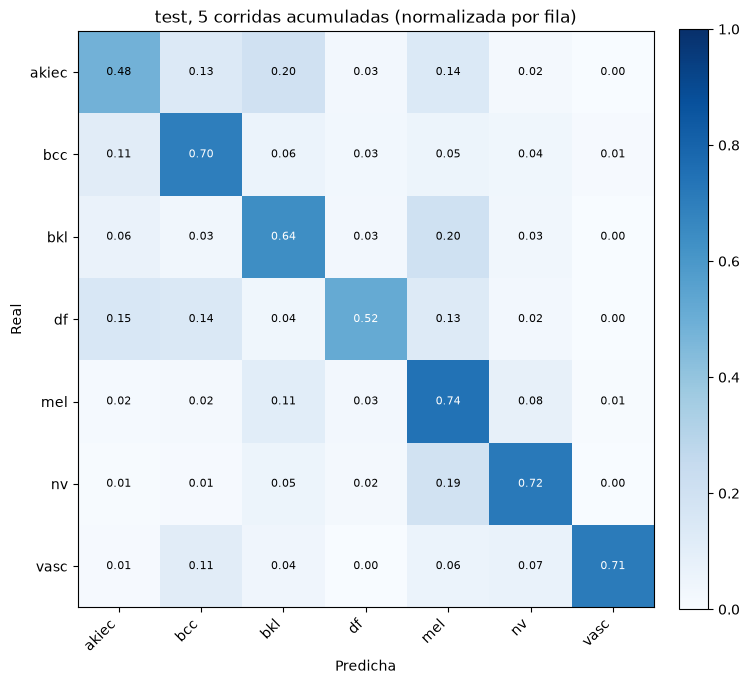

In [19]:
show(results.plot_pooled_confusion(corridas, split="test"))

Costo computacional por corrida (con la inferencia por imagen en validación, test y train) y épocas
de la fase B ejecutadas y restauradas.

In [20]:
results.add_mean_std(results.cost_table(corridas))

,warmup_s,finetune_s,total_s,epochs_warmup,epochs_finetune,finetune_s_per_epoch,inference_ms_per_image_val,inference_ms_per_image_test,inference_ms_per_image_train,trainable_params_finetune,non_trainable_params_finetune,gpu
s0_f0,81.820164,706.395601,788.215765,5.0,17.000000,41.552682,1.359281,4.892620,1.616959,23548935.0,53120.0,NVIDIA GeForce RTX 3050 6GB Laptop GPU
s0_f1,86.866015,545.457425,632.323440,5.0,12.000000,45.454785,1.353847,2.838214,1.649621,23548935.0,53120.0,NVIDIA GeForce RTX 3050 6GB Laptop GPU
s0_f2,85.766170,415.301774,501.067944,5.0,9.000000,46.144642,1.352811,2.651124,1.603614,23548935.0,53120.0,NVIDIA GeForce RTX 3050 6GB Laptop GPU
s0_f3,93.449865,902.185786,995.635651,5.0,22.000000,41.008445,1.353523,2.764472,1.603171,23548935.0,53120.0,NVIDIA GeForce RTX 3050 6GB Laptop GPU
s0_f4,78.825008,525.309122,604.134130,5.0,12.000000,43.775760,1.354042,2.782268,1.356352,23548935.0,53120.0,NVIDIA GeForce RTX 3050 6GB Laptop GPU
mean,85.345444,618.929942,704.275386,5.0,14.400000,43.587263,1.354701,3.185740,1.565943,23548935.0,53120.0,NaN
std,5.547848,189.414634,192.636581,0.0,5.128353,2.283264,0.002603,0.956593,0.118678,0.0,0.0,NaN


In [21]:
results.restored_epochs_table(corridas)

,finetune_run,finetune_best
s0_f0,17.000000,12.000000
s0_f1,12.000000,7.000000
s0_f2,9.000000,4.000000
s0_f3,22.000000,17.000000
s0_f4,12.000000,7.000000
mean,14.400000,9.400000
std,5.128353,5.128353


### 5.3 Curvas de entrenamiento

Curvas de todas las corridas definitivas superpuestas: una línea fina por corrida y la media por
época global en negro (con las corridas que llegan a esa época). La línea discontinua marca el paso
de la fase A a la B.

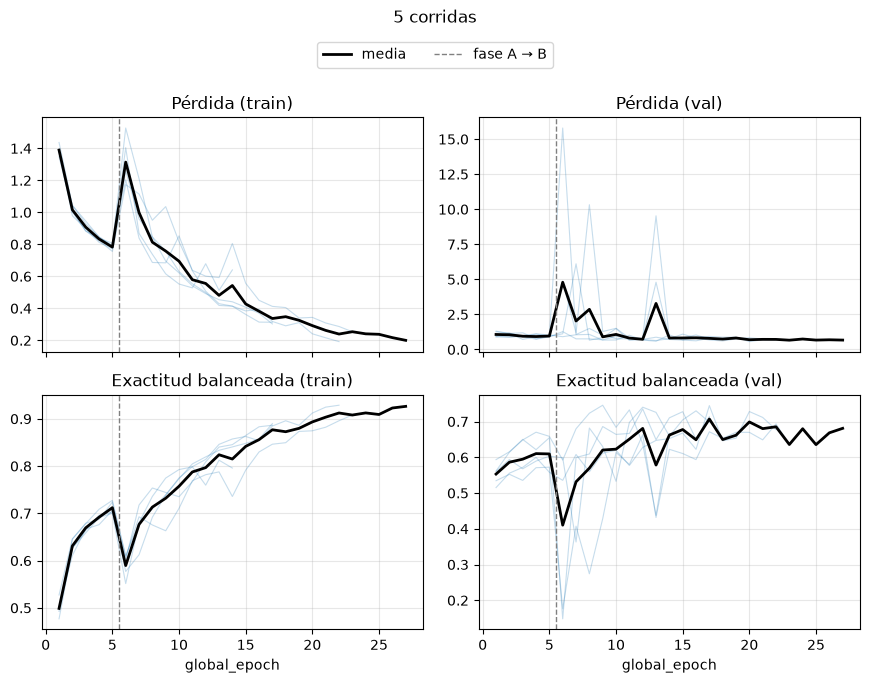

In [22]:
show(results.plot_training_curves_overlay(results.load_histories(corridas)))

## 6. Evaluación

Análisis de las predicciones guardadas de las corridas definitivas sobre `evaluation.split` (test),
con los parámetros de la sección `evaluation` de `base.yaml`. Carga de las probabilidades de todas
las corridas y de los metadatos.

In [23]:
pred_test = evaluation.load_predictions(corridas, cfg_eval["split"])
metadatos = evaluation.load_metadata_or_missing(cfg)
evaluation.predictions_summary(pred_test)

,valor
corridas,5
imagenes,1431
predicciones,7155


### 6.1 Robustez por subgrupos

Exactitud balanceada, exactitud y F1 macro de test por fuente (`dataset`), método diagnóstico
(`dx_type`) y localización: media y desviación estándar entre corridas e imágenes por corrida. F1
macro se promedia sobre las clases presentes en cada subgrupo. `pocas_imagenes` marca los subgrupos
con menos de `subgroup_min_n` imágenes.

In [24]:
subgrupos = evaluation.subgroup_report(pred_test, metadatos, cfg_eval["subgroups"],
                                       cfg_eval["subgroup_metrics"], cfg_eval["subgroup_min_n"])
show(subgrupos)

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pr

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:614: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pr

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


**dataset**

,n_imagenes,corridas,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,pocas_imagenes
dataset,,,,,,,,,
vidir_molemax,567.0,5,0.763980,0.044670,0.931570,0.041162,0.662341,0.057607,False
vidir_modern,455.0,5,0.561974,0.045516,0.568791,0.035926,0.518312,0.011418,False
rosendahl,330.0,5,0.522950,0.019183,0.512121,0.031125,0.490734,0.030842,False
vienna_dias,79.0,5,0.457857,0.161711,0.567089,0.107185,0.329620,0.135850,False


**dx_type**

,n_imagenes,corridas,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,pocas_imagenes
dx_type,,,,,,,,,
histo,776.0,5,0.536066,0.028055,0.543557,0.023185,0.508142,0.030721,False
follow_up,530.0,5,0.944528,0.045997,0.944528,0.045997,0.971000,0.024974,False
consensus,118.0,5,0.723002,0.062780,0.605085,0.073782,0.749351,0.064968,False
confocal,7.0,5,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,True


**localization**

,n_imagenes,corridas,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,pocas_imagenes
localization,,,,,,,,,
back,323.0,5,0.701846,0.040265,0.617337,0.005181,0.589930,0.016977,False
lower extremity,310.0,5,0.600570,0.085580,0.742581,0.052730,0.541418,0.102386,False
trunk,197.0,5,0.633730,0.060041,0.819289,0.033209,0.585918,0.028407,False
upper extremity,156.0,5,0.689332,0.057675,0.694872,0.031923,0.629352,0.052303,False
abdomen,147.0,5,0.656035,0.044004,0.759184,0.022868,0.572657,0.030730,False
face,84.0,5,0.530817,0.077933,0.621429,0.048650,0.529562,0.063218,False
foot,59.0,5,0.477756,0.171125,0.708475,0.059201,0.463481,0.090292,False
chest,52.0,5,0.678254,0.122495,0.565385,0.068802,0.584805,0.093730,False
unknown,34.0,5,0.643750,0.167341,0.594118,0.104815,0.667792,0.117024,False


Exactitud balanceada por subgrupo con la desviación estándar entre corridas como barra de error;
en gris, los subgrupos con pocas imágenes.

**dataset**

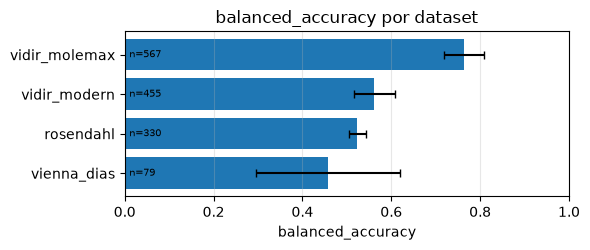

**dx_type**

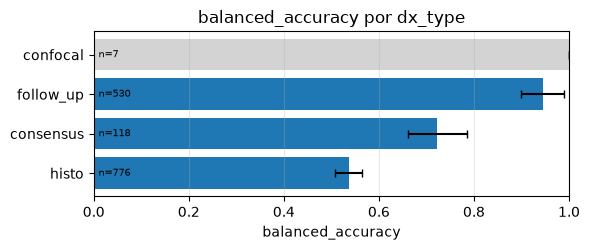

**localization**

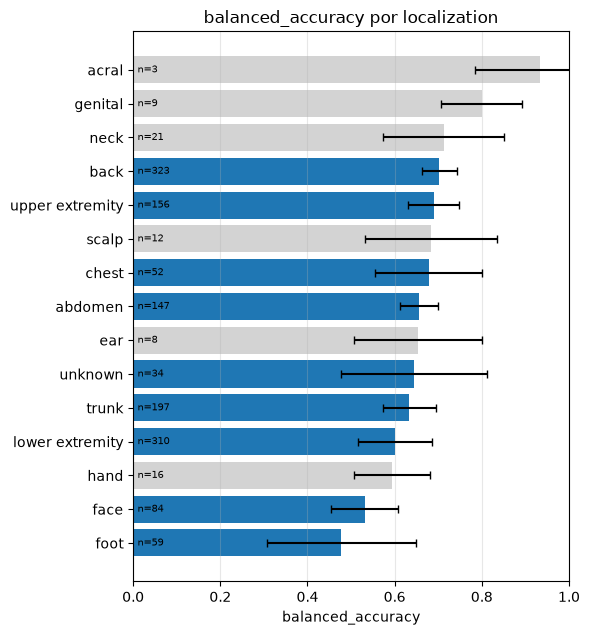

In [25]:
show(evaluation.plot_subgroup_report(subgrupos, "balanced_accuracy"))

### 6.2 Diagnóstico de sobreajuste

Métricas en el train de cada corrida (sin aumento de datos y sin dropout), en validación y en test,
y las brechas train - val y val - test: media y desviación estándar entre corridas.

In [26]:
sobreajuste = evaluation.overfitting_table(corridas, cfg_eval["overfitting_metrics"])
evaluation.overfitting_summary(sobreajuste, cfg_eval["overfitting_metrics"])

,train_mean,train_std,val_mean,val_std,test_mean,test_std,gap_train_val_mean,gap_train_val_std,gap_val_test_mean,gap_val_test_std
balanced_accuracy,0.861679,0.055734,0.731855,0.021875,0.643394,0.015510,0.129824,0.071254,0.088461,0.032826
accuracy,0.766339,0.034335,0.706779,0.026730,0.699371,0.021054,0.059561,0.032937,0.007408,0.009407
f1_macro,0.743902,0.042024,0.633644,0.025596,0.583265,0.022749,0.110258,0.048914,0.050379,0.019667
cross_entropy,0.573860,0.080785,0.757435,0.099864,0.788187,0.097461,-0.183576,0.086103,-0.030751,0.015142


Exactitud balanceada en train, validación y test por corrida y su media.

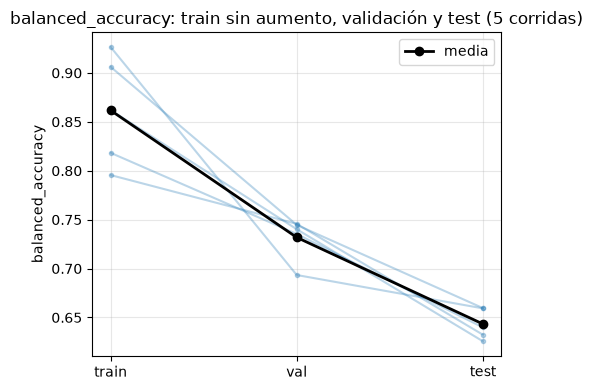

In [27]:
show(evaluation.plot_overfitting(sobreajuste, "balanced_accuracy"))

Valores por corrida.

In [28]:
sobreajuste

,balanced_accuracy_train,balanced_accuracy_val,balanced_accuracy_test,balanced_accuracy_gap_train_val,balanced_accuracy_gap_val_test,accuracy_train,accuracy_val,accuracy_test,accuracy_gap_train_val,accuracy_gap_val_test,f1_macro_train,f1_macro_val,f1_macro_test,f1_macro_gap_train_val,f1_macro_gap_val_test,cross_entropy_train,cross_entropy_val,cross_entropy_test,cross_entropy_gap_train_val,cross_entropy_gap_val_test
s0_f0,0.906165,0.744615,0.659631,0.161550,0.084985,0.740061,0.668608,0.671558,0.071453,-0.002950,0.737456,0.609043,0.568936,0.128413,0.040108,0.672341,0.932770,0.957787,-0.260429,-0.025017
s0_f1,0.818291,0.735339,0.639861,0.082952,0.095478,0.757099,0.718695,0.706499,0.038404,0.012196,0.698636,0.613864,0.567804,0.084772,0.046060,0.582072,0.708320,0.744441,-0.126247,-0.036121
s0_f2,0.795563,0.745689,0.632423,0.049874,0.113266,0.769477,0.739662,0.721174,0.029815,0.018488,0.724456,0.672626,0.613266,0.051829,0.059360,0.566111,0.688948,0.709845,-0.122837,-0.020897
s0_f3,0.926426,0.693414,0.659324,0.233012,0.034089,0.823795,0.712289,0.714186,0.111506,-0.001897,0.811602,0.629636,0.602208,0.181966,0.027428,0.448943,0.742353,0.759423,-0.293410,-0.017070
s0_f4,0.861951,0.740217,0.625731,0.121735,0.114485,0.741264,0.694639,0.683438,0.046625,0.011201,0.747362,0.643051,0.564113,0.104310,0.078938,0.599832,0.714787,0.769437,-0.114954,-0.054650
mean,0.861679,0.731855,0.643394,0.129824,0.088461,0.766339,0.706779,0.699371,0.059561,0.007408,0.743902,0.633644,0.583265,0.110258,0.050379,0.573860,0.757435,0.788187,-0.183576,-0.030751
std,0.055734,0.021875,0.015510,0.071254,0.032826,0.034335,0.026730,0.021054,0.032937,0.009407,0.042024,0.025596,0.022749,0.048914,0.019667,0.080785,0.099864,0.097461,0.086103,0.015142


### 6.3 Análisis de errores

Sensibilidad (`recall`) y precisión por clase en test: media y desviación estándar entre corridas.

In [29]:
results.per_class_summary(por_clase_test, cols=("recall", "precision"))

recall           precision          
           mean       std      mean       std
class                                        
akiec  0.482609  0.156310  0.441983  0.043593
bcc    0.697297  0.067972  0.633009  0.048927
bkl    0.636943  0.038744  0.556826  0.044637
df     0.517647  0.064438  0.307007  0.228641
mel    0.743396  0.065421  0.340695  0.020303
nv     0.715866  0.042692  0.967007  0.014810
vasc   0.710000  0.065192  0.814804  0.097795

Pares de clases más confundidos en la matriz de test acumulada: conteo, porcentaje sobre las
imágenes de la clase real y sobre el total de errores.

In [30]:
evaluation.confused_pairs_from_runs(corridas, cfg_eval["split"], cfg_eval["top_confused_pairs"])

,real,predicha,conteo,pct_de_la_clase_real,pct_de_los_errores
0,nv,mel,921,19.227557,42.817294
1,nv,bkl,244,5.093946,11.343561
2,bkl,mel,159,20.254777,7.391911
3,nv,df,103,2.150313,4.788470
4,mel,bkl,85,10.691824,3.951650
5,mel,nv,65,8.176101,3.021850
6,nv,bcc,55,1.148225,2.556950
7,bkl,akiec,51,6.496815,2.370990
8,akiec,bkl,45,19.565217,2.092050
9,bcc,akiec,41,11.081081,1.906090


Tasa de error en las imágenes marcadas en `data/atipicos_imagenes.csv` frente a las no marcadas,
por tipo de marca (Mahalanobis robusta, al menos `univariate_min_marks` marcas univariadas, o
cualquiera). El archivo cubre solo las imágenes de train, así que se usan las predicciones de
validación de cada corrida (fuera de pliegue).

In [31]:
pred_val = evaluation.load_predictions(corridas, cfg_eval["outliers"]["split"])
evaluation.outlier_error_rates(pred_val, evaluation.outlier_flags(cfg))

,n_marcadas,error_marcadas_mean,error_marcadas_std,n_no_marcadas,error_no_marcadas_mean,error_no_marcadas_std,diferencia
marca,,,,,,,
mahalanobis,662.0,0.378097,0.034527,1055.0,0.239964,0.022930,0.138133
univariante,788.0,0.352042,0.024815,928.0,0.243246,0.027055,0.108796
cualquiera,933.0,0.347888,0.024978,783.0,0.228353,0.028380,0.119534


### 6.4 Casos difíciles

Imágenes de test que fallan en más de `hard_cases.min_error_frac` de las corridas, y su número por
clase real.

In [32]:
cfg_dificiles = cfg_eval["hard_cases"]
frecuencia = evaluation.image_error_frequency(pred_test)
evaluation.hard_cases_by_class(frecuencia, cfg_dificiles["min_error_frac"])

,imagenes,dificiles,pct_dificiles
label,,,
akiec,46,24,52.173913
bcc,74,19,25.675676
bkl,157,53,33.757962
df,17,7,41.176471
mel,159,35,22.012579
nv,958,260,27.139875
vasc,20,5,25.000000


In [33]:
dificiles = evaluation.hard_cases(frecuencia, cfg_dificiles["min_error_frac"])
dificiles

,label,corridas,errores,p_real_media,frac_error,pred_erronea_frecuente
image_id,,,,,,
ISIC_0029891,df,5,5,0.001720,1.0,bcc
ISIC_0030230,bcc,5,5,0.004689,1.0,nv
ISIC_0034001,nv,5,5,0.006191,1.0,mel
ISIC_0024973,df,5,5,0.007221,1.0,mel
ISIC_0032905,nv,5,5,0.008419,1.0,mel
...,...,...,...,...,...,...
ISIC_0030754,mel,5,3,0.523362,0.6,nv
ISIC_0032058,nv,5,3,0.524912,0.6,mel
ISIC_0032074,nv,5,3,0.526405,0.6,mel


Cuadrícula de los casos difíciles con image_id, clase real, predicción errónea más frecuente y
fracción de corridas con error.

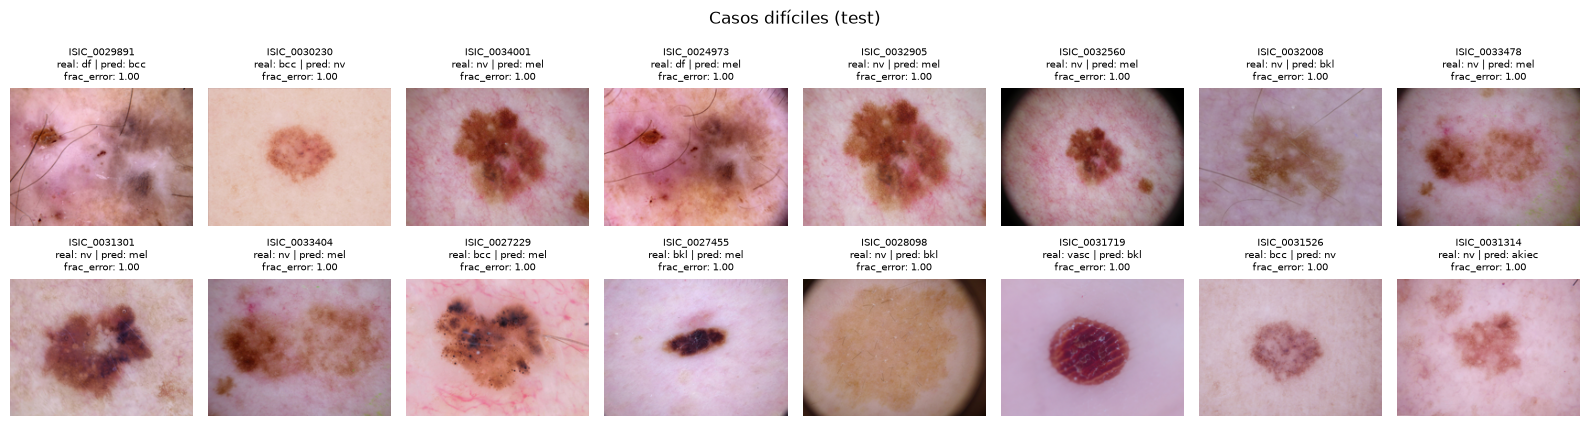

In [34]:
show(evaluation.plot_case_grid(cfg, dificiles, "pred_erronea_frecuente", "frac_error",
                               n=cfg_dificiles["grid_n"], ncols=cfg_dificiles["grid_ncols"],
                               title="Casos difíciles (test)"))

Errores con mayor confianza: una fila por imagen, con la corrida en que la probabilidad de la clase
predicha fue mayor.

In [35]:
errores_confiados = evaluation.confident_errors(pred_test, cfg_dificiles["grid_n"])
errores_confiados

,image_id,run,label,pred,confidence
0,ISIC_0024861,s0_f0,nv,df,0.999945
1,ISIC_0031749,s0_f1,bcc,df,0.999894
2,ISIC_0026506,s0_f4,mel,vasc,0.999800
3,ISIC_0029429,s0_f0,nv,df,0.999542
4,ISIC_0024539,s0_f3,akiec,bkl,0.999106
5,ISIC_0024982,s0_f3,bkl,akiec,0.998997
6,ISIC_0026171,s0_f0,akiec,bkl,0.998678
7,ISIC_0031112,s0_f0,nv,df,0.998676
8,ISIC_0030910,s0_f0,mel,df,0.998672
9,ISIC_0032560,s0_f0,nv,mel,0.998620


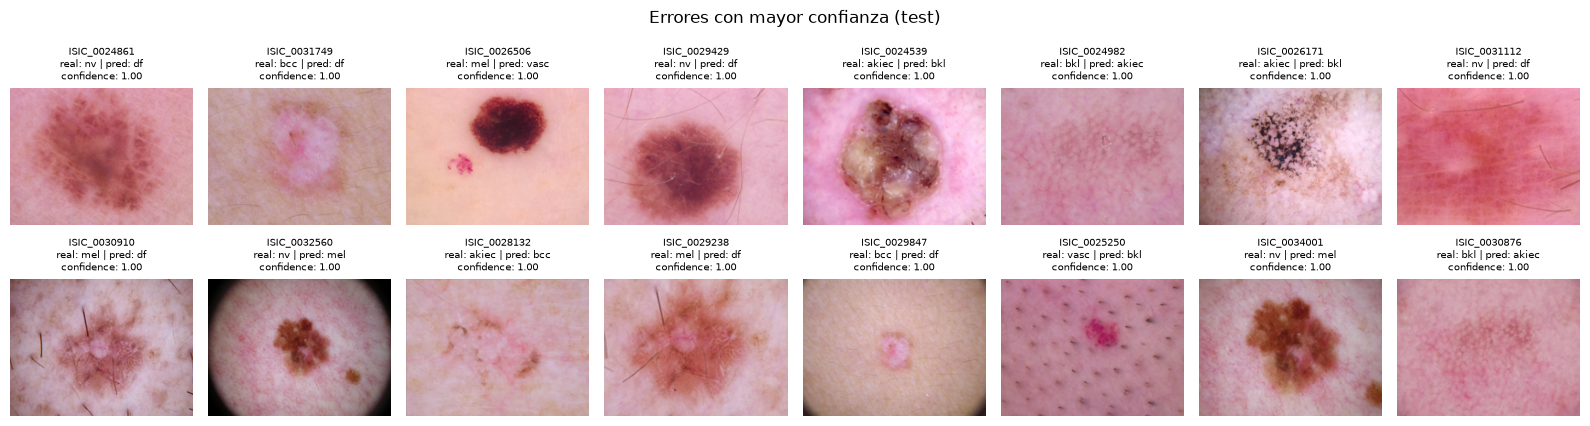

In [36]:
show(evaluation.plot_case_grid(cfg, errores_confiados, "pred", "confidence",
                               n=cfg_dificiles["grid_n"], ncols=cfg_dificiles["grid_ncols"],
                               title="Errores con mayor confianza (test)"))

### 6.5 Calibración

ECE de cada corrida en test (intervalos de igual ancho en la confianza, como `train.ece_bins`), con
la confianza media y la exactitud.

In [37]:
evaluation.calibration_by_run(pred_test, cfg_eval["calibration_bins"])

,ece,confianza_media,exactitud
s0_f0,0.153034,0.820115,0.671558
s0_f1,0.085839,0.790089,0.706499
s0_f2,0.067422,0.784192,0.721174
s0_f3,0.097664,0.811850,0.714186
s0_f4,0.107577,0.789600,0.683438
mean,0.102307,0.799169,0.699371
std,0.032057,0.015794,0.021054


Diagrama de fiabilidad: exactitud frente a confianza media por intervalo, una línea por corrida y
una con todas las corridas juntas; debajo, el histograma de confianzas.

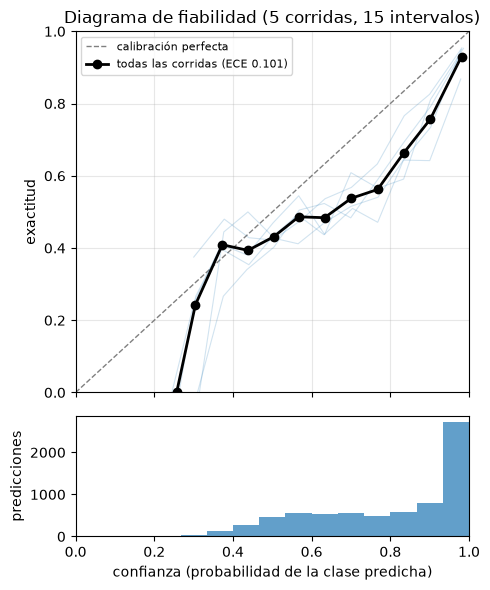

In [38]:
show(evaluation.plot_reliability(pred_test, cfg_eval["calibration_bins"]))

Valores por intervalo con todas las corridas juntas.

In [39]:
evaluation.pooled_reliability(pred_test, cfg_eval["calibration_bins"])

,desde,hasta,n,confianza_media,exactitud,brecha
0,0.000000,0.066667,0,NaN,NaN,NaN
1,0.066667,0.133333,0,NaN,NaN,NaN
2,0.133333,0.200000,0,NaN,NaN,NaN
3,0.200000,0.266667,3,0.256774,0.000000,0.256774
4,0.266667,0.333333,37,0.304621,0.243243,0.061378
5,0.333333,0.400000,132,0.373005,0.409091,0.036086
6,0.400000,0.466667,277,0.438175,0.393502,0.044673
7,0.466667,0.533333,457,0.503287,0.431072,0.072214
8,0.533333,0.600000,553,0.567059,0.486438,0.080621
9,0.600000,0.666667,531,0.632799,0.483992,0.148807


### 6.6 Mapas de saliencia (Grad-CAM)

Grad-CAM respecto de la clase predicha sobre la capa `gradcam_layer` del YAML del modelo, con los
pesos de la corrida definitiva `evaluation.gradcam.run`. Muestra fija de test: por clase,
`per_class_correct` aciertos y `per_class_wrong` errores, elegidos con `sample_seed`.

In [40]:
cfg_gradcam = cfg_eval["gradcam"]
corrida_gradcam = gradcam.gradcam_run_dir(cfg, MODELO)
muestra = gradcam.sample_images(corrida_gradcam, cfg_gradcam["per_class_correct"],
                                cfg_gradcam["per_class_wrong"], cfg_gradcam["sample_seed"])
muestra

,image_id,label,pred,resultado,confidence
0,ISIC_0025780,akiec,akiec,acierto,0.973327
1,ISIC_0031012,akiec,akiec,acierto,0.827815
2,ISIC_0027254,akiec,bkl,error,0.772981
3,ISIC_0029002,akiec,bcc,error,0.799470
4,ISIC_0024984,bcc,bcc,acierto,0.995254
5,ISIC_0027846,bcc,bcc,acierto,0.713093
6,ISIC_0028495,bcc,mel,error,0.766742
7,ISIC_0032139,bcc,bkl,error,0.384342
8,ISIC_0031980,bkl,bkl,acierto,0.997630
9,ISIC_0033539,bkl,bkl,acierto,0.976752


Cada par de filas muestra la imagen redimensionada como en el entrenamiento y, debajo, el mapa
superpuesto (rojo = mayor contribución a la clase predicha).

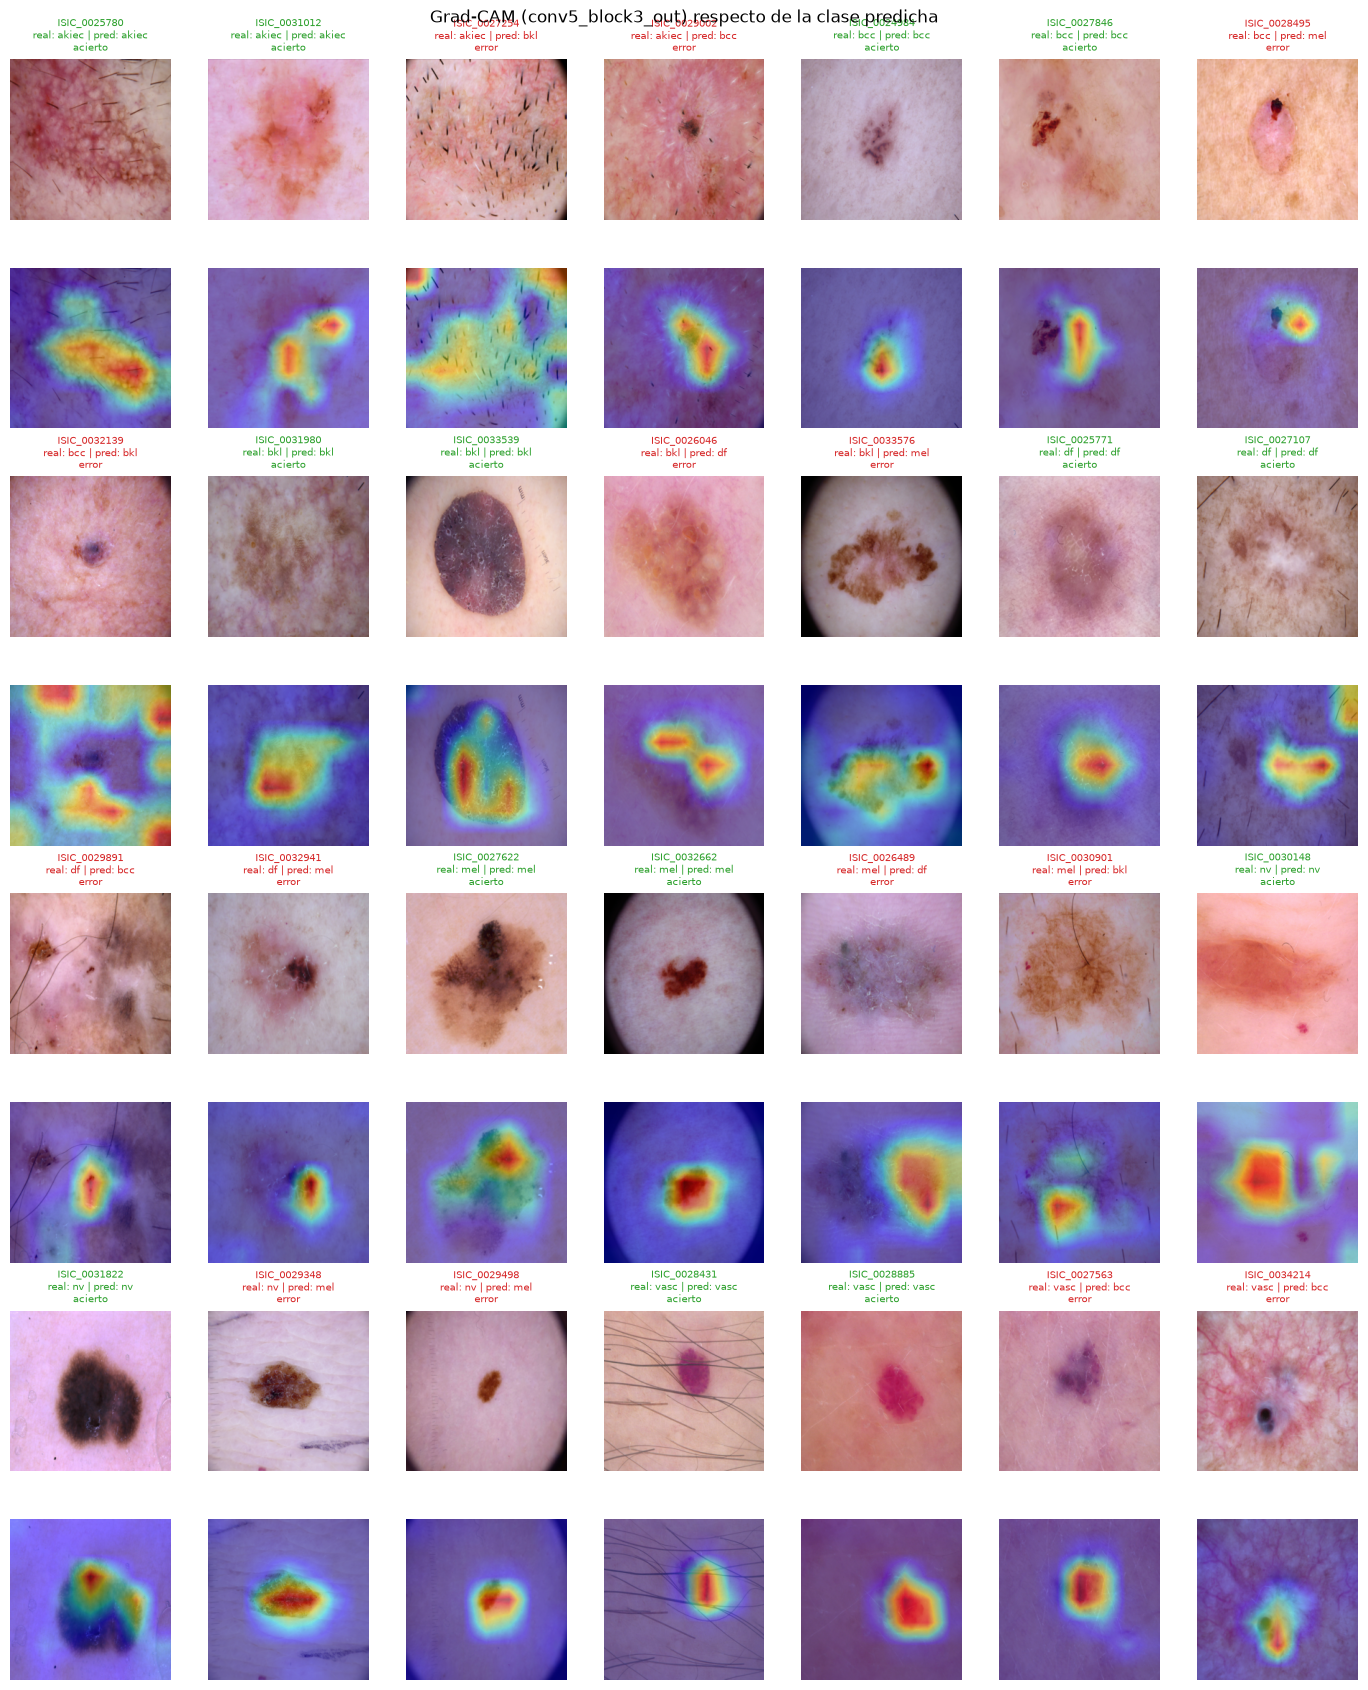

In [41]:
mapas = gradcam.compute_gradcam(cfg, MODELO, corrida_gradcam, muestra)
show(gradcam.plot_gradcam_grid(mapas, alpha=cfg_gradcam["alpha"], ncols=cfg_gradcam["ncols"]))